## ANALISI COVID


Carico qui il documento in cartella locale tramite filepath

In [1]:
import pandas as pd
import os

# Path portabile: il CSV viene cercato nella stessa cartella del notebook
file_path = "owid-covid-data.csv"
if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"'{file_path}' non trovato nella cartella corrente ({os.getcwd()}). "
        "Assicurati che il file CSV sia nella stessa cartella del notebook."
    )

covid19_df = pd.read_csv(file_path)
covid19_df

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
429430,ZWE,Africa,Zimbabwe,2024-07-31,266386.0,0.0,0.0,5740.0,0.0,0.0,...,30.7,36.79,1.7,61.49,0.57,16320539,NaN,NaN,NaN,NaN
429431,ZWE,Africa,Zimbabwe,2024-08-01,266386.0,0.0,0.0,5740.0,0.0,0.0,...,30.7,36.79,1.7,61.49,0.57,16320539,NaN,NaN,NaN,NaN
429432,ZWE,Africa,Zimbabwe,2024-08-02,266386.0,0.0,0.0,5740.0,0.0,0.0,...,30.7,36.79,1.7,61.49,0.57,16320539,NaN,NaN,NaN,NaN
429433,ZWE,Africa,Zimbabwe,2024-08-03,266386.0,0.0,0.0,5740.0,0.0,0.0,...,30.7,36.79,1.7,61.49,0.57,16320539,NaN,NaN,NaN,NaN


## PANORAMICA GENERALE DEI DATI PRESENTI

In [2]:
covid19_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 429435 entries, 0 to 429434
Data columns (total 67 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   iso_code                                    429435 non-null  object 
 1   continent                                   402910 non-null  object 
 2   location                                    429435 non-null  object 
 3   date                                        429435 non-null  object 
 4   total_cases                                 411804 non-null  float64
 5   new_cases                                   410159 non-null  float64
 6   new_cases_smoothed                          408929 non-null  float64
 7   total_deaths                                411804 non-null  float64
 8   new_deaths                                  410608 non-null  float64
 9   new_deaths_smoothed                         409378 non-null  float64
 

In [3]:
covid19_df.shape

(429435, 67)

Notiamo tramite i due metodi posti in essere come **.info()** e **.shape()** che a differenza per numero di contenuti per colonna possono esserci dati nulli nel DataFrame

Identifichiamo che siano presenti le aree geografiche di interesse per poter rappresentare i dati dei contaggiati per ogni continente della colonna **"continent"**

In [4]:
case_for_cont=covid19_df["continent"].unique()
case_for_cont

array(['Asia', nan, 'Europe', 'Africa', 'Oceania', 'North America',
       'South America'], dtype=object)

In [5]:
grouped_1 = covid19_df.groupby("continent")["total_cases"].sum()
int_group1 = grouped_1.astype(int)
int_group1

continent
Africa            14616886098
Asia             252167317226
Europe           236756684151
North America    127073670231
Oceania           11598053992
South America     73484570403
Name: total_cases, dtype: int64

In [6]:
grouped_2=[]
grouped_1 = covid19_df.groupby("continent")["total_cases"].sum()
int_group1 = grouped_1.astype(int)
grouped_2=(int_group1/int_group1.sum())*100
print(grouped_2.round(2))

continent
Africa            2.04
Asia             35.23
Europe           33.08
North America    17.76
Oceania           1.62
South America    10.27
Name: total_cases, dtype: float64


In [7]:
covid19_italy=covid19_df[covid19_df["location"].str.contains("Italy",regex=False)].copy()
covid19_italy

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
185275,ITA,Europe,Italy,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,27.8,NaN,3.18,83.51,0.89,59037472,-1904.1,-12.37,-12.37,-32.0
185276,ITA,Europe,Italy,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,27.8,NaN,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN
185277,ITA,Europe,Italy,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,27.8,NaN,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN
185278,ITA,Europe,Italy,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,27.8,NaN,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN
185279,ITA,Europe,Italy,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,27.8,NaN,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
186947,ITA,Europe,Italy,2024-08-03,26774728.0,0.0,2239.29,197301.0,0.0,4.86,...,27.8,NaN,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN
186948,ITA,Europe,Italy,2024-08-04,26781078.0,6350.0,907.14,197307.0,6.0,0.86,...,27.8,NaN,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN
186949,ITA,Europe,Italy,2024-08-05,NaN,NaN,NaN,NaN,NaN,NaN,...,27.8,NaN,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN
186950,ITA,Europe,Italy,2024-08-06,NaN,NaN,NaN,NaN,NaN,NaN,...,27.8,NaN,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN


In [8]:
covid19_italy.loc[:,"datetime"]=pd.to_datetime(covid19_italy.loc[:,"date"], format="mixed", dayfirst=True).copy()
covid19_italy["datetime"]

185275   2020-01-05
185276   2020-01-06
185277   2020-01-07
185278   2020-01-08
185279   2020-01-09
            ...    
186947   2024-08-03
186948   2024-08-04
186949   2024-08-05
186950   2024-08-06
186951   2024-08-07
Name: datetime, Length: 1677, dtype: datetime64[ns]

In [9]:
covid19_italy.loc[:,"year"]=covid19_italy.loc[:,"datetime"].dt.year 
covid19_italy_2022=covid19_italy[covid19_italy["year"]== 2022]
covid19_italy_2022

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million,datetime,year
186002,ITA,Europe,Italy,2022-01-01,5622431.0,0.0,36797.00,136530.0,0.0,140.86,...,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN,2022-01-01,2022
186003,ITA,Europe,Italy,2022-01-02,6267035.0,644604.0,92086.29,137513.0,983.0,140.43,...,3.18,83.51,0.89,59037472,168226.3,12.99,8.06,2849.48,2022-01-02,2022
186004,ITA,Europe,Italy,2022-01-03,6267035.0,0.0,92086.29,137513.0,0.0,140.43,...,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN,2022-01-03,2022
186005,ITA,Europe,Italy,2022-01-04,6267035.0,0.0,92086.29,137513.0,0.0,140.43,...,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN,2022-01-04,2022
186006,ITA,Europe,Italy,2022-01-05,6267035.0,0.0,92086.29,137513.0,0.0,140.43,...,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN,2022-01-05,2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
186362,ITA,Europe,Italy,2022-12-27,25060503.0,0.0,18918.14,184168.0,0.0,114.00,...,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN,2022-12-27,2022
186363,ITA,Europe,Italy,2022-12-28,25060503.0,0.0,18918.14,184168.0,0.0,114.00,...,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN,2022-12-28,2022
186364,ITA,Europe,Italy,2022-12-29,25060503.0,0.0,18918.14,184168.0,0.0,114.00,...,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN,2022-12-29,2022
186365,ITA,Europe,Italy,2022-12-30,25060503.0,0.0,18918.14,184168.0,0.0,114.00,...,3.18,83.51,0.89,59037472,NaN,NaN,NaN,NaN,2022-12-30,2022


In [10]:
covid19_italy_2022.info()

<class 'pandas.core.frame.DataFrame'>
Index: 365 entries, 186002 to 186366
Data columns (total 69 columns):
 #   Column                                      Non-Null Count  Dtype         
---  ------                                      --------------  -----         
 0   iso_code                                    365 non-null    object        
 1   continent                                   365 non-null    object        
 2   location                                    365 non-null    object        
 3   date                                        365 non-null    object        
 4   total_cases                                 365 non-null    float64       
 5   new_cases                                   365 non-null    float64       
 6   new_cases_smoothed                          365 non-null    float64       
 7   total_deaths                                365 non-null    float64       
 8   new_deaths                                  365 non-null    float64       
 9   new_dea

In [11]:
# Punto 3: in Italia i nuovi casi vengono registrati su base settimanale, quindi
# la maggior parte dei giorni non ha una misurazione reale (new_cases == 0).
# Filtriamo via quei giorni, tenendo solo i giorni che hanno una misurazione.
covid19_italy_2022_filt = covid19_italy_2022[covid19_italy_2022["new_cases"] != 0].copy()
print(f"Giorni del 2022: {len(covid19_italy_2022)}  ->  giorni con misurazione: {len(covid19_italy_2022_filt)}")
covid19_italy_2022_filt

Giorni del 2022: 365  ->  giorni con misurazione: 52


,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million,datetime,year
186003,ITA,Europe,Italy,2022-01-02,6267035.0,644604.0,92086.29,137513.0,983.0,140.43,...,3.18,83.51,0.89,59037472,168226.30,12.99,8.06,2849.48,2022-01-02,2022
186010,ITA,Europe,Italy,2022-01-09,7281297.0,1014262.0,144894.57,138881.0,1368.0,195.43,...,3.18,83.51,0.89,59037472,168831.80,12.89,3.94,2859.74,2022-01-09,2022
186017,ITA,Europe,Italy,2022-01-16,8549450.0,1268153.0,181164.71,140856.0,1975.0,282.14,...,3.18,83.51,0.89,59037472,170089.10,12.83,8.03,2881.04,2022-01-16,2022
186024,ITA,Europe,Italy,2022-01-23,9781191.0,1231741.0,175963.00,143296.0,2440.0,348.57,...,3.18,83.51,0.89,59037472,171694.19,12.80,10.40,2908.22,2022-01-23,2022
186031,ITA,Europe,Italy,2022-01-30,10821375.0,1040184.0,148597.71,145914.0,2618.0,374.00,...,3.18,83.51,0.89,59037472,174151.69,12.84,16.50,2949.85,2022-01-30,2022
186038,ITA,Europe,Italy,2022-02-06,11542793.0,721418.0,103059.71,148542.0,2628.0,375.43,...,3.18,83.51,0.89,59037472,176219.19,12.85,13.98,2984.87,2022-02-06,2022
186045,ITA,Europe,Italy,2022-02-13,12053330.0,510537.0,72933.86,150824.0,2282.0,326.00,...,3.18,83.51,0.89,59037472,177489.48,12.81,8.88,3006.39,2022-02-13,2022
186052,ITA,Europe,Italy,2022-02-20,12427773.0,374443.0,53491.86,152848.0,2024.0,289.14,...,3.18,83.51,0.89,59037472,178007.39,12.72,3.66,3015.16,2022-02-20,2022
186059,ITA,Europe,Italy,2022-02-27,12732680.0,304907.0,43558.14,154416.0,1568.0,224.00,...,3.18,83.51,0.89,59037472,178015.30,12.60,0.06,3015.29,2022-02-27,2022
186066,ITA,Europe,Italy,2022-03-06,12990223.0,257543.0,36791.86,155782.0,1366.0,195.14,...,3.18,83.51,0.89,59037472,178133.80,12.48,0.86,3017.30,2022-03-06,2022


Dopo aver modificato il tabulato filtrando solo i dati del 2022 in italia, andiamo quindi a selezionare nella finale i dati necessari per effettuare un grafico

In [12]:
covid19_italy_2022dt=covid19_italy_2022_filt.set_index("datetime")
covid19_italy_2022dt=covid19_italy_2022dt[["location","total_cases","new_cases"]]
covid19_italy_2022dt

,location,total_cases,new_cases
datetime,,,
2022-01-02,Italy,6267035.0,644604.0
2022-01-09,Italy,7281297.0,1014262.0
2022-01-16,Italy,8549450.0,1268153.0
2022-01-23,Italy,9781191.0,1231741.0
2022-01-30,Italy,10821375.0,1040184.0
2022-02-06,Italy,11542793.0,721418.0
2022-02-13,Italy,12053330.0,510537.0
2022-02-20,Italy,12427773.0,374443.0
2022-02-27,Italy,12732680.0,304907.0


<Axes: title={'center': 'Italia 2022 - Evoluzione dei casi totali'}, xlabel='datetime'>

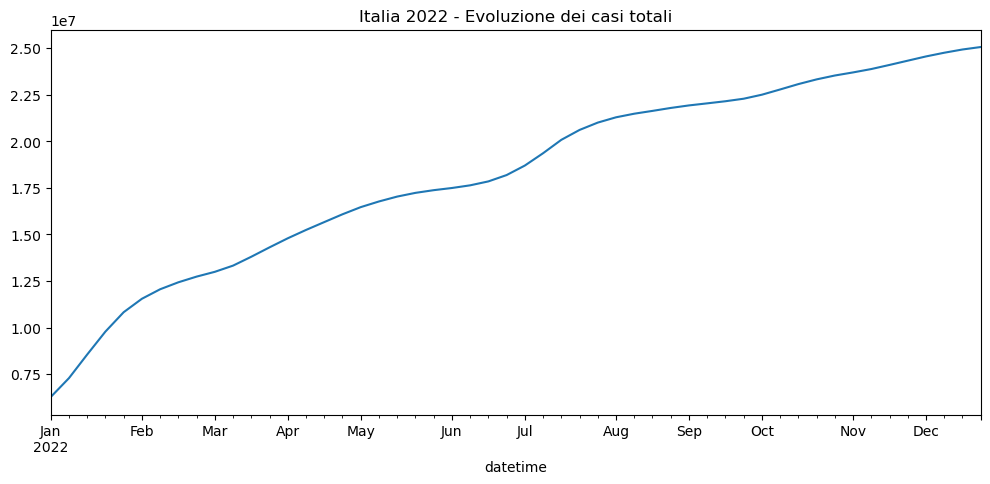

In [13]:
# Punto 3a: evoluzione dei casi TOTALI dall'inizio alla fine del 2022
covid19_italy_2022dt["total_cases"].plot(
    title="Italia 2022 - Evoluzione dei casi totali", figsize=(12, 5)
)

<Axes: title={'center': 'Italia 2022 - Nuovi casi per data'}, xlabel='datetime'>

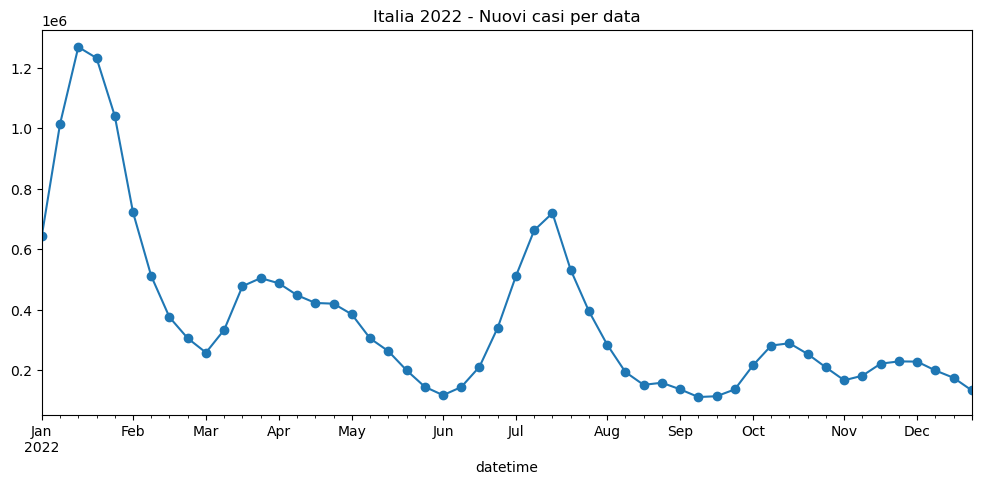

In [14]:
# Punto 3b: numero di NUOVI casi rispetto alla data (solo giorni con misurazione)
covid19_italy_2022dt["new_cases"].plot(
    title="Italia 2022 - Nuovi casi per data", figsize=(12, 5), marker="o"
)

Si analizza la differenza quantitativa grafica del numero totale di pazienti in terapia intensiva **icu_patients** tra Germania, Francia e Italia

In [15]:
covid19_df["date"] = pd.to_datetime(covid19_df["date"],format="mixed")
covid19_df["month"]=covid19_df["date"].dt.month
covid19_df["year"]=covid19_df["date"].dt.year
covid19_2=covid19_df.groupby(["location","year","month","date"])["icu_patients"].sum().reset_index()
covid19_2

,location,year,month,date,icu_patients
0,Afghanistan,2020,1,2020-01-05,0.0
1,Afghanistan,2020,1,2020-01-06,0.0
2,Afghanistan,2020,1,2020-01-07,0.0
3,Afghanistan,2020,1,2020-01-08,0.0
4,Afghanistan,2020,1,2020-01-09,0.0
...,...,...,...,...,...
421660,Zimbabwe,2024,7,2024-07-31,0.0
421661,Zimbabwe,2024,8,2024-08-01,0.0
421662,Zimbabwe,2024,8,2024-08-02,0.0
421663,Zimbabwe,2024,8,2024-08-03,0.0


In [16]:
covid19_igf=covid19_2[covid19_2["location"].str.contains("Germany|France|Italy")]
covid19_igf

,location,year,month,date,icu_patients
128633,France,2020,1,2020-01-05,0.0
128634,France,2020,1,2020-01-06,0.0
128635,France,2020,1,2020-01-07,0.0
128636,France,2020,1,2020-01-08,0.0
128637,France,2020,1,2020-01-09,0.0
...,...,...,...,...,...
183871,Italy,2024,8,2024-08-03,55.0
183872,Italy,2024,8,2024-08-04,56.0
183873,Italy,2024,8,2024-08-05,56.0
183874,Italy,2024,8,2024-08-06,51.0


In [17]:
covid19_igf_gr=covid19_igf.groupby(["location","year","month","date"])["icu_patients"].sum().reset_index()
covid19_igf_gr

,location,year,month,date,icu_patients
0,France,2020,1,2020-01-05,0.0
1,France,2020,1,2020-01-06,0.0
2,France,2020,1,2020-01-07,0.0
3,France,2020,1,2020-01-08,0.0
4,France,2020,1,2020-01-09,0.0
...,...,...,...,...,...
5020,Italy,2024,8,2024-08-03,55.0
5021,Italy,2024,8,2024-08-04,56.0
5022,Italy,2024,8,2024-08-05,56.0
5023,Italy,2024,8,2024-08-06,51.0


In [18]:
filter_covid1920223 = (covid19_igf_gr["date"]>="2022-05-01") & (covid19_igf_gr["date"]<="2023-04-30")
covid19_igf20223=covid19_igf_gr[filter_covid1920223]
covid19_igf20223

,location,year,month,date,icu_patients
847,France,2022,5,2022-05-01,1557.0
848,France,2022,5,2022-05-02,1511.0
849,France,2022,5,2022-05-03,1498.0
850,France,2022,5,2022-05-04,1465.0
851,France,2022,5,2022-05-05,1447.0
...,...,...,...,...,...
4555,Italy,2023,4,2023-04-26,100.0
4556,Italy,2023,4,2023-04-27,99.0
4557,Italy,2023,4,2023-04-28,105.0
4558,Italy,2023,4,2023-04-29,111.0


<Axes: xlabel='location', ylabel='icu_patients'>

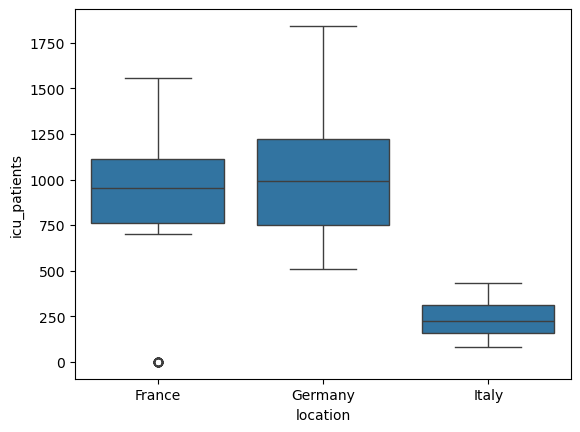

In [19]:
import seaborn as sns
sns.boxplot(data=covid19_igf20223, x="location",y="icu_patients")

**Il risultato è un box plot che mostra la distribuzione dei pazienti in terapia intensiva attraverso diverse località, visualizzando quartili, mediana e potenziali valori anomali per ogni località, nel periodo compreso tra Maggio 2022 e Aprile 2023. Inoltre possiamo notare e differenze di volume tra i paesi in base all'altezza delle corrispettive mediane, portando a considerare la Germania (solo per una rilevanza di ordine di centesimi superiore alla Francia) il paese maggiormente più in difficoltà sanitaria durante la gestione della pandemia Covid19**

In [20]:
covid19_df["date"] = pd.to_datetime(covid19_df["date"],format="mixed")
covid19_df["month"]=covid19_df["date"].dt.month
covid19_df["year"]=covid19_df["date"].dt.year
# min_count=1: se il valore grezzo e' NaN resta NaN (senza min_count la somma di NaN diventerebbe 0,
# mascherando i dati mancanti). Cosi' il successivo controllo dei nulli e' veritiero.
covid19_2_1=covid19_df.groupby(["location","year","month","date"])["hosp_patients"].sum(min_count=1).reset_index()
covid19_2_1

,location,year,month,date,hosp_patients
0,Afghanistan,2020,1,2020-01-05,NaN
1,Afghanistan,2020,1,2020-01-06,NaN
2,Afghanistan,2020,1,2020-01-07,NaN
3,Afghanistan,2020,1,2020-01-08,NaN
4,Afghanistan,2020,1,2020-01-09,NaN
...,...,...,...,...,...
421660,Zimbabwe,2024,7,2024-07-31,NaN
421661,Zimbabwe,2024,8,2024-08-01,NaN
421662,Zimbabwe,2024,8,2024-08-02,NaN
421663,Zimbabwe,2024,8,2024-08-03,NaN


In [21]:
covid19_gfs1=covid19_2_1[covid19_2_1["location"].str.contains("Italy|Germany|France|Spain")].copy()
filter_date = (covid19_gfs1["date"]>="2021-01-01") & (covid19_gfs1["date"]<="2021-12-31")
covid19_gfs = covid19_gfs1[filter_date]
covid19_gfs

,location,year,month,date,hosp_patients
128995,France,2021,1,2021-01-01,24263.0
128996,France,2021,1,2021-01-02,24458.0
128997,France,2021,1,2021-01-03,24780.0
128998,France,2021,1,2021-01-04,24962.0
128999,France,2021,1,2021-01-05,24871.0
...,...,...,...,...,...
357881,Spain,2021,12,2021-12-27,8024.0
357882,Spain,2021,12,2021-12-28,8580.0
357883,Spain,2021,12,2021-12-29,8916.0
357884,Spain,2021,12,2021-12-30,8982.0


In [22]:
covid19_gfs.isnull().sum()

location           0
year               0
month              0
date               0
hosp_patients    365
dtype: int64

**Punto 5b - Verifica dei dati nulli**

Grazie all'aggregazione con `min_count=1`, i valori mancanti vengono preservati come `NaN` e il controllo `isnull().sum()` risulta ora veritiero. Emerge che **la Germania ha tutti i 365 giorni del 2021 nulli** per la colonna `hosp_patients`, mentre Francia, Italia e Spagna non presentano dati mancanti.

**È possibile gestirli tramite sostituzione?** In questo caso **no**: la Germania non ha alcun dato di ricovero nel periodo, quindi non esiste alcun valore reale su cui basare una sostituzione (media, interpolazione o forward-fill). Sostituire con 0 o con la media falserebbe l'analisi facendo apparire la Germania come priva di ricoveri, cosa non vera. La scelta corretta è **mantenere i `NaN`** (che nei grafici vengono semplicemente non tracciati) e segnalare il buco come dato non riportato dalla fonte, come descritto di seguito.

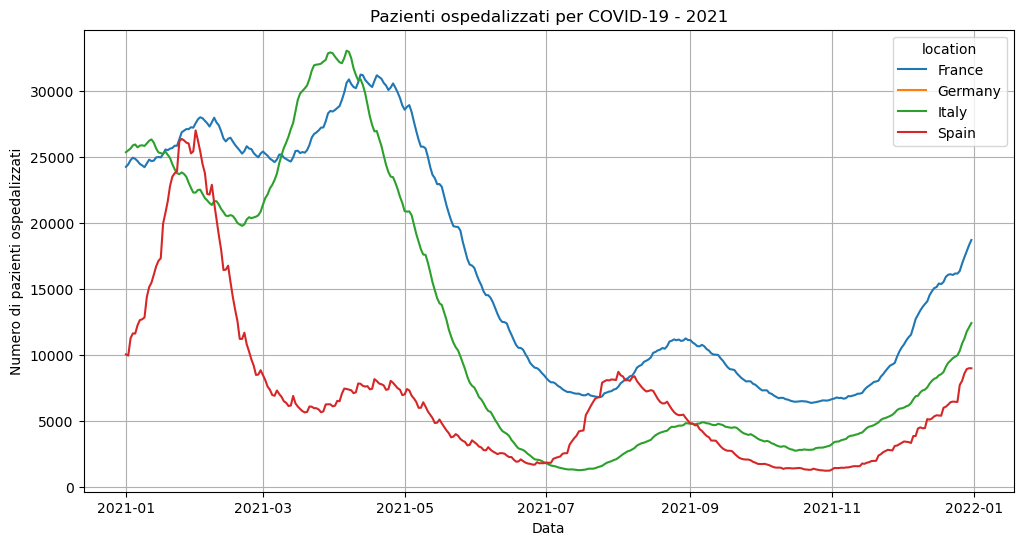

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
sns.lineplot(data=covid19_gfs, x="date", y="hosp_patients", hue="location")
plt.title("Pazienti ospedalizzati per COVID-19 - 2021")
plt.xlabel("Data")
plt.ylabel("Numero di pazienti ospedalizzati")
plt.grid(True)
plt.show()

In [24]:
cov_germany=covid19_gfs[covid19_gfs["location"]=="Germany"]
cov_germany

,location,year,month,date,hosp_patients
139039,Germany,2021,1,2021-01-01,NaN
139040,Germany,2021,1,2021-01-02,NaN
139041,Germany,2021,1,2021-01-03,NaN
139042,Germany,2021,1,2021-01-04,NaN
139043,Germany,2021,1,2021-01-05,NaN
...,...,...,...,...,...
139399,Germany,2021,12,2021-12-27,NaN
139400,Germany,2021,12,2021-12-28,NaN
139401,Germany,2021,12,2021-12-29,NaN
139402,Germany,2021,12,2021-12-30,NaN


Il dataset Our World in Data (OWID) sul COVID-19 raccoglie dati da fonti nazionali diverse (ECDC, ministeri della salute, ospedali), e la disponibilità dei dati su ricoveri e terapie intensive varia moltissimo da paese a paese, a differenza di metriche come casi totali o decessi, che sono più standardizzate a livello internazionale.
Per la Germania specificamente, è un fatto abbastanza noto che:

Il sistema tedesco di reporting ospedaliero (basato su strutture come il DIVI-Intensivregister per le terapie intensive) non sempre ha alimentato in modo continuo il dataset OWID, specialmente nei primi mesi/anni della pandemia.
Alcuni paesi riportano dati di ricovero su base settimanale invece che giornaliera, e OWID a volte lascia vuoti i giorni intermedi invece di interpolare.
Ci sono stati periodi in cui la fonte dati per un paese è cambiata o si è interrotta temporaneamente, creando "buchi" nella serie storica.